# Teste M — Open Field completo, do vídeo bruto aos gráficos

**Pipeline reproduzível por sessão:** upload no Colab → calibração do piso, borda e oclusões → detector Faster R-CNN Wistar → HRNet-W32 adaptada (27 pontos) → análise comportamental → gráficos científicos e vídeo anotado com legenda **fora** da arena.

**ATENÇÃO:** esta é uma aplicação exploratória. Os pesos foram adaptados para uma sessão anterior; em vídeos novos, valide as caixas e os keypoints antes de interpretar as métricas. O módulo de *rearing* sinaliza **possíveis candidatos**, não diagnósticos nem eventos confirmados. Não estima ângulo espinhal 3D real, nem identifica apoio anterior.

### Como operar
1. Selecione uma GPU T4/A100/L4 no Colab **se disponível**. É necessário apenas para inferência de vídeos inéditos. Execute a seção **1** e envie seu vídeo no seletor de upload (ou use a opção de Drive).
2. Execute **2**: gere um calibrador HTML **desse vídeo**, baixe-o e abra-o no navegador. Marque **verde: piso**, **ciano: borda visível**, **roxo: oclusão**. Exporte o JSON.
3. Execute **3** e importe o JSON. Confira a prévia da geometria. **Não use Run all desde o início:** as etapas 1–3 pedem interação.
4. Execute **4 em diante**, até o final. A inferência leva o tempo necessário, mas usa cache por vídeo e pesos. Não repita as células de GPU se o cache já estiver completo.
5. Baixe os gráficos PNG/SVG, relatórios CSV/JSON e o MP4 do Drive. Para recalcular apenas métricas e gráficos, altere `MODO='SOMENTE_GRAFICOS'`.

### Limitações científicas
- Centro/periferia: definido pelo `mouse_center` projetado na geometria. Pontos fora do chão são **posições de solo incertas**, não prova de rearing ou perda total de pose.
- Distância/velocidade: calculadas só entre frames consecutivos válidos, sem ligar lacunas; quando não existem dimensões reais da caixa, usam unidades normalizadas.
- Escore de possível rearing: regra de triagem baseada em geometria e pose parcial, **não validada**. Não some eventos como rearing confirmado.
- Gráficos estilo Prism: PNG 300 dpi, SVG editável; sem testes estatísticos automáticos.

**Modelos exigidos no Drive**: `DeepLabCut/Wistar/modelos/best_detector.pth`, `modelos/HRNet_adaptada/snapshot-hrnet_w32-001.pt` e `modelos/HRNet_adaptada/pytorch_config.yaml`.

## 1 — Configurar, montar Drive e enviar um vídeo novo

In [ ]:
from pathlib import Path

# Primeiro uso: True exibe seletor para você enviar um MP4/MOV diretamente ao Colab.
# Se o vídeo já estiver no Drive, mude para False e preencha VIDEO_EXISTENTE_NO_DRIVE.
FAZER_UPLOAD_AGORA = False
VIDEO_EXISTENTE_NO_DRIVE ='/content/drive/MyDrive/DeepLabCut/Wistar/novos_videos/rat02track.mp4'

PASTA_VIDEOS = Path('/content/drive/MyDrive/DeepLabCut/Wistar/novos_videos')
PASTA_GEOMETRIAS = Path('/content/drive/MyDrive/DeepLabCut/Wistar/geometrias_openfield')
PASTA_RESULTADOS = Path('/content/drive/MyDrive/DeepLabCut/Wistar/teste_M_openfield_completo')
PASTA_MODELOS = Path('/content/drive/MyDrive/DeepLabCut/Wistar/modelos')

MODO = 'INFERIR_E_ANALISAR'  # ou 'SOMENTE_GRAFICOS' para repetir gráficos sem GPU
FPS_ANALISE = 24
CONFIANCA_POSE = 0.60
CONFIANCA_DETECTOR = 0.30
MARGEM_CAIXA_DETECTOR = 0.12
FRAMES_CHECKPOINT_DETECTOR = 250
BATCH_HRNET = 2  # começar em 2 para evitar falta de VRAM na T4

# Medidas INTERNAS reais, do piso físico, não da moldura (preencha ambas ou nenhuma).
ARENA_LARGURA_CM = 0.50
ARENA_ALTURA_CM = 0.40
FRAC_CENTRO_X = 0.50
FRAC_CENTRO_Y = 0.50
MARGEM_ZONA_INDETERMINADA = 0.0
DURACAO_MIN_ENTRADA_CENTRO_S = 0.20
DURACAO_MIN_BAIXA_VELOCIDADE_S = 0.50
DURACAO_MIN_EVENTO_ACELERACAO_S = 0.20
LIMIAR_POUCO_MOVIMENTO_CM_S = 2.0
LIMITE_VELOCIDADE_CM_S_PARA_EXCLUIR = None
JANELA_MEDIANA_VELOCIDADE = 5

GERAR_PREVIEW = True
PREVIEW_INICIO_S = 0
PREVIEW_DURACAO_S = 20
GERAR_VIDEO_COMPLETO_ANOTADO = True
RENDERIZAR_NOVAMENTE = True  # True para refletir novas alterações; False para usar MP4 já salvo
FPS_VIDEO_ANOTADO = 12  # quadro original preservado, apenas reduz densidade temporal do MP4
ALTURA_BARRA_SUPERIOR_PX = 118

# Regras não supervisionadas SOMENTE para selecionar candidatos a rearing.
GERAR_CANDIDATOS_REARING = True
LIMIAR_CANDIDATO = 0.62
DURACAO_MIN_CANDIDATO_S = 0.25

assert MODO in ('INFERIR_E_ANALISAR','SOMENTE_GRAFICOS')
assert FPS_ANALISE % FPS_VIDEO_ANOTADO == 0
assert (ARENA_LARGURA_CM is None)==(ARENA_ALTURA_CM is None)
print('Modo:',MODO,'| Inferência do vídeo inédito requer GPU disponível.')


Modo: INFERIR_E_ANALISAR | Inferência do vídeo inédito requer GPU disponível.


In [ ]:
import os, sys, json, math, hashlib, shutil, subprocess, time, base64, re, importlib.util, zipfile
import numpy as np, pandas as pd, cv2
from IPython.display import display, Image, Markdown, HTML
from google.colab import drive, files

if not Path('/content/drive/MyDrive').exists(): drive.mount('/content/drive')
for p in (PASTA_VIDEOS,PASTA_GEOMETRIAS,PASTA_RESULTADOS): p.mkdir(parents=True,exist_ok=True)

if FAZER_UPLOAD_AGORA:
    print('Selecione um arquivo de vídeo. Para vídeos muito grandes, envie primeiro ao Drive e use VIDEO_EXISTENTE_NO_DRIVE.')
    uploads=files.upload()
    assert len(uploads)==1, 'Envie um vídeo de cada vez; depois altere FAZER_UPLOAD_AGORA=False.'
    name=next(iter(uploads))
    assert Path(name).suffix.lower() in ('.mp4','.mov','.avi','.mkv'), f'Extensão de vídeo inválida: {name}'
    src=Path(name)
    dst=PASTA_VIDEOS/src.name
    # Um arquivo com o mesmo nome pode ter conteúdo diferente; substituir sempre no upload.
    shutil.copy2(src,dst)
    VIDEO_ORIG=dst
else:
    assert VIDEO_EXISTENTE_NO_DRIVE.strip(), 'Preencha VIDEO_EXISTENTE_NO_DRIVE com o caminho exato de um vídeo.'
    VIDEO_ORIG=Path(VIDEO_EXISTENTE_NO_DRIVE)
    assert VIDEO_ORIG.is_file(),f'Vídeo não encontrado: {VIDEO_ORIG}'

cap=cv2.VideoCapture(str(VIDEO_ORIG))
assert cap.isOpened(), 'Não consegui abrir o vídeo. Converta para MP4/H.264 antes de tentar novamente.'
VIDEO_W=int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)); VIDEO_H=int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT));cap.release()
print('Vídeo:',VIDEO_ORIG.name,'| tamanho:',VIDEO_ORIG.stat().st_size//1024**2,'MB | resolução:',VIDEO_W,'x',VIDEO_H)

def get_sha256(path):
    d=hashlib.sha256()
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(4*1024*1024),b''): d.update(b)
    return d.hexdigest()

VIDEO_SHA=get_sha256(VIDEO_ORIG)
VIDEO_KEY=re.sub(r'[^a-zA-Z0-9_-]','_',VIDEO_ORIG.stem)+'_'+VIDEO_SHA[:12]
VIDEO_CALIB_NAME=VIDEO_KEY+'.json'
GEOMETRY_PATH=PASTA_GEOMETRIAS/VIDEO_CALIB_NAME
OUT_DIR=PASTA_RESULTADOS/VIDEO_KEY
OUT_DIR.mkdir(parents=True,exist_ok=True)
print('Sessão isolada:',VIDEO_KEY,'\nCalibração:',GEOMETRY_PATH)


Vídeo: rat02track.mp4 | tamanho: 48 MB | resolução: 1280 x 720
Sessão isolada: rat02track_e1f5f99d6726 
Calibração: /content/drive/MyDrive/DeepLabCut/Wistar/geometrias_openfield/rat02track_e1f5f99d6726.json


## 2 — Calibrar o vídeo (piso, borda visível e oclusões)

Esta etapa gera um HTML com um frame **do vídeo recém-enviado**. Ele é totalmente local, não contém o vídeo completo e funciona offline. Você pode marcar as três estruturas no mesmo editor. A **borda visível da caixa** é um contorno independente; as conexões tracejadas são apenas uma guia de perspectiva, não uma reconstrução 3D.

Por enquanto, o calibrador aceita **pisos quadriláteros**. Para arenas circulares ou paredes irregulares, será necessária uma geometria diferente.

O HTML será baixado pelo Colab e também salvo no Drive. Abra-o no navegador, faça a marcação, clique em **Exportar JSON** e execute a etapa 3 para enviar esse JSON de volta ao Colab. Isso evita as células `eval_js()` que ficavam bloqueadas.

In [ ]:
from IPython.display import display, Image
from google.colab import files

def frame_calibracao(v):
    cap=cv2.VideoCapture(str(v)); assert cap.isOpened()
    n=int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.set(cv2.CAP_PROP_POS_FRAMES, min(48,max(0,n//10)))
    ok,frame=cap.read()
    if not ok: cap.set(cv2.CAP_PROP_POS_FRAMES,0);ok,frame=cap.read()
    cap.release()
    assert ok, 'Não foi possível extrair um frame para calibração.'
    return frame

CAL_TEMPLATE = "<!doctype html><html lang=\"pt-BR\"><head><meta charset=\"utf-8\"><meta name=\"viewport\" content=\"width=device-width,initial-scale=1\" />\n<title>Calibração Open Field — __NAME__</title><style>\n*{box-sizing:border-box}body{margin:0;padding:16px;background:#101921;color:#eaf2f7;font:15px/1.5 system-ui,Arial}main{max-width:1400px;margin:auto}h2{margin:5px 0 10px}.p{background:#1b2b36;border:1px solid #3c5360;border-radius:12px;padding:14px;margin:12px 0}.toolbar{display:flex;flex-wrap:wrap;gap:8px;align-items:center}button,select{background:#28506a;border:1px solid #668ea1;color:white;padding:9px 10px;border-radius:7px;font:inherit;cursor:pointer}button:hover{background:#396780}canvas{border-radius:8px;border:1px solid #577081;display:block;width:100%;height:auto;touch-action:none}small{color:#b3cbd7}b.green{color:#30ea8d}b.cyan{color:#43d8ff}b.purple{color:#c9a0ff}.hint{font-size:13px;color:#d4e8ec}\n</style></head><body><main><h2>Geometria da arena — __NAME__</h2><p>Marque <b class=\"green\">piso físico verde</b> (quatro cantos internos), <b class=\"cyan\">borda visível ciano</b> (contorno superior visível da caixa, caso identificável) e <b class=\"purple\">oclusão roxa</b> (a região onde a parede esconde o animal ou o piso). A linha verde pode ficar atrás da parede devido à perspectiva. Os contornos NÃO têm de coincidir.</p>\n<div class=\"p\"><div class=\"toolbar\"><label for=\"mode\">Editar:</label><select id=\"mode\"><option value=\"floor\">🟢 Piso físico — arrastar vértices</option><option value=\"rim\">🔷 Borda visível — arrastar vértices</option><option value=\"occlusion\">🟣 Oclusão — polígono livre</option></select><button id=\"start\">Marcar 4 cantos do modo atual</button><button id=\"finish\">Finalizar polígono</button><button id=\"undo\">Desfazer último ponto</button><button id=\"clear\">Limpar oclusões</button><button id=\"save\">Exportar JSON</button></div><small id=\"status\">Arraste os vértices existentes para refinar.</small></div>\n<div class=\"p\"><canvas id=\"c\" width=\"__W__\" height=\"__H__\"></canvas></div>\n<div class=\"p hint\"><b>Ordem dos quatro vértices:</b> superior esquerdo → superior direito → inferior direito → inferior esquerdo (na imagem). A borda ciano é opcional quando a estrutura não estiver identificável; não invente uma borda. Para polígono roxo, clique nos pontos da faixa escondida e pressione “Finalizar polígono”. Os pontos não devem ser extrapolados para fora da imagem.</div>\n<script>\nconst im=new Image(); im.src='data:image/jpeg;base64,__IMG__';\nconst c=document.getElementById('c'),ctx=c.getContext('2d'),sel=document.getElementById('mode');\nconst st=document.getElementById('status');\nlet floor=__FLOOR__,rim=__RIM__,occlusions=[],draft=[],fresh=false,drag=null;\nconst colors={floor:'#30e889',rim:'#42d8ff',occlusion:'#bf8aff'};\nfunction pt(e){let r=c.getBoundingClientRect();return [Math.round((e.clientX-r.left)*c.width/r.width*10)/10,Math.round((e.clientY-r.top)*c.height/r.height*10)/10];}\nfunction line(points,color,close=true,fill=false,dash=false){if(!points||!points.length)return;ctx.save();ctx.beginPath();ctx.moveTo(...points[0]);points.slice(1).forEach(p=>ctx.lineTo(...p));if(close&&points.length>2)ctx.closePath();ctx.lineWidth=3;ctx.strokeStyle=color;if(dash)ctx.setLineDash([6,5]);ctx.stroke();if(fill&&points.length>2){ctx.globalAlpha=.23;ctx.fillStyle=color;ctx.fill();}ctx.restore()}\nfunction dot(p,color,idx){ctx.beginPath();ctx.arc(p[0],p[1],7,0,Math.PI*2);ctx.fillStyle=color;ctx.fill();ctx.fillStyle='#0c121b';ctx.font='bold 12px system-ui';ctx.fillText(String(idx+1),p[0]+8,p[1]-8)}\nfunction render(){ctx.clearRect(0,0,c.width,c.height);ctx.drawImage(im,0,0,c.width,c.height);for(let p of occlusions)line(p,colors.occlusion,true,true);line(floor,colors.floor);line(rim,colors.rim);if(floor&&rim&&floor.length===4&&rim.length===4){for(let i=0;i<4;i++)line([floor[i],rim[i]],'#ffffff',false,false,true)}(floor||[]).forEach((p,i)=>dot(p,colors.floor,i));(rim||[]).forEach((p,i)=>dot(p,colors.rim,i));if(draft.length){line(draft,'#f1d05d',false);draft.forEach((p,i)=>dot(p,'#f1d05d',i))}}\nfunction near(points,p){if(!points)return -1;for(let i=0;i<points.length;i++)if(Math.hypot(points[i][0]-p[0],points[i][1]-p[1])<17)return i;return -1}\nc.addEventListener('pointerdown',e=>{const p=pt(e),mode=sel.value;if(fresh){draft.push(p);if(draft.length===4){if(mode==='floor')floor=draft.map(x=>x.slice());else if(mode==='rim')rim=draft.map(x=>x.slice());fresh=false;draft=[];st.textContent='Quatro vértices definidos. Arraste para ajustar.';}render();return;}if(mode==='occlusion'){draft.push(p);render();return;}const points=mode==='floor'?floor:rim;const i=near(points,p);if(i>=0){drag={mode,i};c.setPointerCapture(e.pointerId)}});\nc.addEventListener('pointermove',e=>{if(!drag)return;const p=pt(e);p[0]=Math.max(0,Math.min(c.width,p[0]));p[1]=Math.max(0,Math.min(c.height,p[1]));(drag.mode==='floor'?floor:rim)[drag.i]=p;render()});c.addEventListener('pointerup',()=>drag=null);c.addEventListener('pointercancel',()=>drag=null);\nsel.addEventListener('change',()=>{fresh=false;draft=[];render()});\ndocument.getElementById('start').onclick=()=>{if(sel.value==='occlusion'){st.textContent='No modo roxo clique livremente e finalize o polígono.';return}fresh=true;draft=[];st.textContent='Clique nos quatro cantos: superior esquerdo, superior direito, inferior direito, inferior esquerdo.';render()};\ndocument.getElementById('finish').onclick=()=>{if(sel.value!=='occlusion'||draft.length<3){st.textContent='Selecione o modo roxo e marque pelo menos 3 pontos.';return}occlusions.push(draft.map(p=>p.slice()));draft=[];render();st.textContent='Oclusão salva; você pode criar outra.'};\ndocument.getElementById('undo').onclick=()=>{draft.pop();render()};document.getElementById('clear').onclick=()=>{occlusions=[];draft=[];render()};\ndocument.getElementById('save').onclick=()=>{if(!floor||floor.length!==4){alert('Marque os 4 cantos do piso');return}\nconst links=(p)=>p&&p.length===4?{top:[p[0],p[1]],right:[p[1],p[2]],bottom:[p[2],p[3]],left:[p[3],p[0]]}:null;\nconst o={schema_version:'1.2',kind:'wistar_arena_geometry_context',source_video:__VIDEO_JS__,source_video_sha256:'__SHA__',image_size:[__W__,__H__],floor_corners_px:floor,box_rim_corners_px:rim,occlusion_polygons:occlusions,visible_floor_polygon:null,wall_contact_lines:links(floor),box_rim_lines:links(rim),notes:'Piso físico, borda visível e oclusões marcados manualmente; geometria 2D, não reconstrução 3D.'};\nconst url=URL.createObjectURL(new Blob([JSON.stringify(o,null,2)],{type:'application/json'}));const a=document.createElement('a');a.href=url;a.download='__CALIB__.json';a.click();setTimeout(()=>URL.revokeObjectURL(url),1500)};\nim.onload=render;\n</script></main></body></html>"
FRAME_CALIB=frame_calibracao(VIDEO_ORIG)
_,jpeg=cv2.imencode('.jpg',FRAME_CALIB,[cv2.IMWRITE_JPEG_QUALITY,85]); assert _
payload=base64.b64encode(jpeg.tobytes()).decode('ascii')
h,w=FRAME_CALIB.shape[:2]
floor_initial=[[.17*w,.11*h],[.83*w,.11*h],[.83*w,.89*h],[.17*w,.89*h]]
rim_initial=None  # não inventar borda da caixa; marque-a explicitamente se for visível
cal_html=(CAL_TEMPLATE.replace('__IMG__',payload).replace('__W__',str(w)).replace('__H__',str(h))
 .replace('__FLOOR__',json.dumps(floor_initial)).replace('__RIM__',json.dumps(rim_initial))
 .replace('__NAME__',__import__('html').escape(VIDEO_ORIG.name)).replace('__VIDEO_JS__',json.dumps(VIDEO_ORIG.name))
 .replace('__CALIB__',VIDEO_KEY).replace('__SHA__',VIDEO_SHA))
CAL_HTML=OUT_DIR/('CALIBRAR_'+VIDEO_KEY+'.html')
CAL_HTML.write_text(cal_html,encoding='utf-8')
print('Calibrador salvo no Drive:',CAL_HTML)
print('O Colab abrirá a caixa de download. Abra o HTML fora do Colab, marque piso/borda/oclusão e exporte JSON.')
files.download(str(CAL_HTML))


Calibrador salvo no Drive: /content/drive/MyDrive/DeepLabCut/Wistar/teste_M_openfield_completo/rat02track_e1f5f99d6726/CALIBRAR_rat02track_e1f5f99d6726.html
O Colab abrirá a caixa de download. Abra o HTML fora do Colab, marque piso/borda/oclusão e exporte JSON.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 3 — Importar JSON da calibração e conferir a imagem

Use o arquivo `...json` exportado pelo HTML. O notebook **verifica o SHA-256** para não aplicar geometria de outro vídeo por engano. Se precisar alterar a geometria depois da inferência, basta importar outro JSON e repetir as análises: **não precisa inferir novamente**.

Selecione o JSON exportado pelo calibrador HTML.


Saving rat02track_e1f5f99d6726.json to rat02track_e1f5f99d6726.json


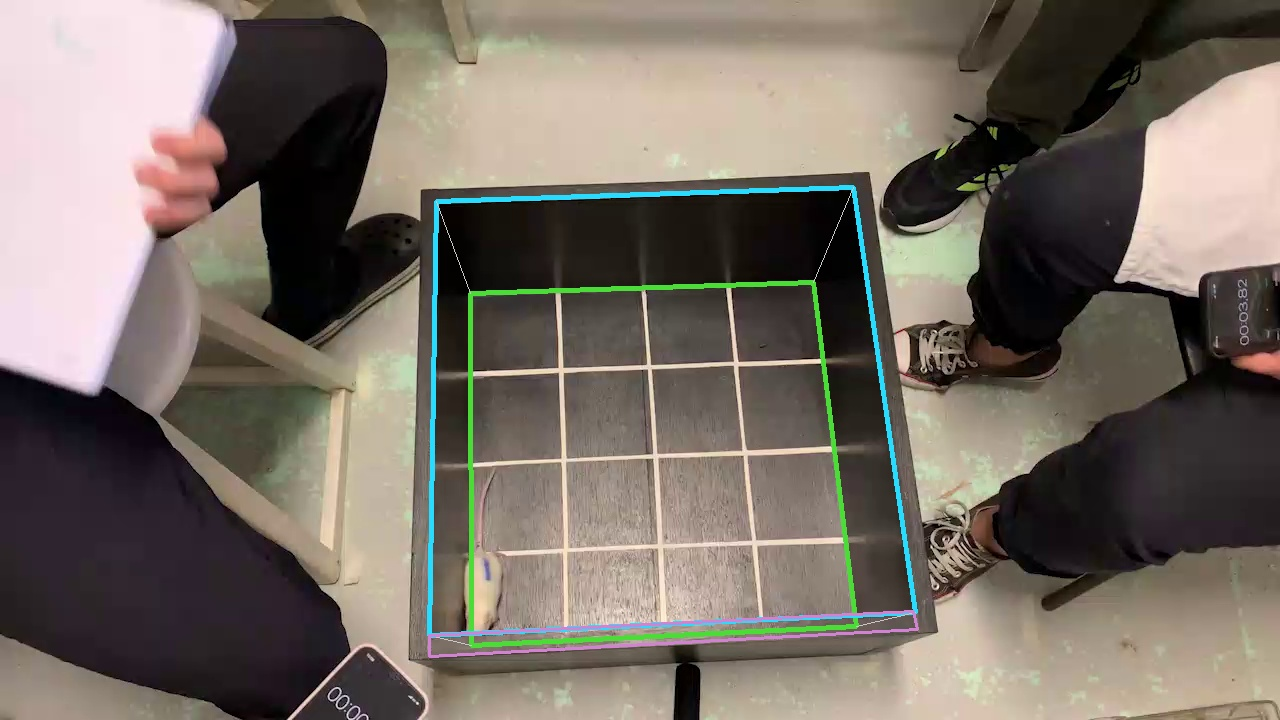

Geom. validada: /content/drive/MyDrive/DeepLabCut/Wistar/geometrias_openfield/rat02track_e1f5f99d6726.json 
Se não estiver correta, corrija no HTML, reimporte e repita esta célula.


In [ ]:
if GEOMETRY_PATH.is_file():
    print('Já existe geometria desta gravação:',GEOMETRY_PATH)
    REIMPORTAR_GEOMETRIA = False  # coloque True se corrigiu o JSON
else:
    REIMPORTAR_GEOMETRIA = True
if REIMPORTAR_GEOMETRIA:
    print('Selecione o JSON exportado pelo calibrador HTML.')
    gup=files.upload()
    assert len(gup)==1, 'Envie um único JSON.'
    incoming=json.loads(next(iter(gup.values())).decode('utf-8'))
    assert incoming.get('source_video_sha256')==VIDEO_SHA, 'JSON de outro vídeo! Calibre esta gravação novamente.'
    assert incoming.get('image_size')==[VIDEO_W,VIDEO_H], 'Dimensões da calibração não coincidem com o vídeo.'
    GEOMETRY_PATH.write_text(json.dumps(incoming,ensure_ascii=False,indent=2),encoding='utf-8')

g=json.loads(GEOMETRY_PATH.read_text(encoding='utf-8'))
assert g.get('source_video_sha256')==VIDEO_SHA, 'A geometria não pertence a este vídeo.'
pts=np.asarray(g['floor_corners_px'],dtype=np.float32)
assert pts.shape==(4,2) and np.isfinite(pts).all() and cv2.isContourConvex(pts), 'Piso inválido ou vértices fora de ordem.'
assert abs(cv2.contourArea(pts)) > .01*VIDEO_W*VIDEO_H, 'Piso pequeno demais.'
assert ((pts[:,0]>=0)&(pts[:,0]<=VIDEO_W)&(pts[:,1]>=0)&(pts[:,1]<=VIDEO_H)).all()
if g.get('box_rim_corners_px') is not None:
    rim=np.asarray(g['box_rim_corners_px'],dtype=np.float32)
    assert rim.shape==(4,2) and np.isfinite(rim).all(), 'Borda da caixa inválida.'
for poly in g.get('occlusion_polygons',[]):
    a=np.asarray(poly,dtype=np.float32)
    assert len(a)>=3 and a.shape[1]==2 and np.isfinite(a).all(), 'Polígono de oclusão inválido.'
preview=FRAME_CALIB.copy()
cv2.polylines(preview,[pts.astype(np.int32)],True,(55,220,75),3)
if g.get('box_rim_corners_px') is not None:
    ri=np.asarray(g['box_rim_corners_px'],dtype=np.float32)
    cv2.polylines(preview,[ri.astype(np.int32)],True,(255,220,40),3)
    for i in range(4):cv2.line(preview,tuple(pts[i].astype(int)),tuple(ri[i].astype(int)),(200,200,200),1)
for poly in g.get('occlusion_polygons',[]):cv2.polylines(preview,[np.asarray(poly,dtype=np.int32)],True,(210,130,210),2)
preview_path=OUT_DIR/'00_GEOMETRIA_VALIDAR.jpg'; cv2.imwrite(str(preview_path),preview)
display(Image(filename=str(preview_path),width=850))
print('Geom. validada:',GEOMETRY_PATH,'\nSe não estiver correta, corrija no HTML, reimporte e repita esta célula.')
GEOMETRIAS={VIDEO_ORIG.name:g}


## 4 — Preparar os modelos e executar detecção + pose

**Para vídeo novo:** ative GPU se disponível. Se houver falta de VRAM na T4, diminua `BATCH_HRNET` para 1. Os checkpoints já existentes do Wistar serão carregados; **não há novo fine-tuning**. Se não houver GPU, pare nesta etapa e retome quando o Colab liberar recursos. O cache em Drive permite recomeçar a detecção.

In [2]:
from pathlib import Path
import torch, torchvision
from torchvision.transforms.functional import to_tensor
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

def get_sha256(path):
    d=hashlib.sha256()
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(4*1024*1024),b''):d.update(b)
    return d.hexdigest()

DET_DRIVE=PASTA_MODELOS/'best_detector.pth'
POSE_DRIVE=PASTA_MODELOS/'HRNet_adaptada/snapshot-hrnet_w32-001.pt'
CFG_DRIVE=PASTA_MODELOS/'HRNet_adaptada/pytorch_config.yaml'
DEVICE=torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print('Dispositivo:',DEVICE, torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else '')

if MODO=='INFERIR_E_ANALISAR':
    for p in [DET_DRIVE,POSE_DRIVE,CFG_DRIVE]:
        assert p.is_file(), f'Checkpoint não encontrado: {p}'
    if importlib.util.find_spec('deeplabcut') is None:
        print('Instalando DeepLabCut 3 (apenas na primeira execução do runtime) ...')
        subprocess.check_call([sys.executable,'-m','pip','install','-q','--pre','deeplabcut[modelzoo]>=3.0,<4'])
    import deeplabcut
    import deeplabcut.pose_estimation_pytorch as pep
    from deeplabcut.pose_estimation_pytorch.config import PoseConfig
    from deeplabcut.pose_estimation_pytorch.apis.videos import create_df_from_prediction
    assert DEVICE.type=='cuda', 'GPU indisponível. Para vídeos inéditos, selecione T4/A100 quando estiver disponível; para resultados já inferidos use SOMENTE_GRAFICOS.'
    LOCAL_MODELOS=Path('/content/openfield_modelos');LOCAL_MODELOS.mkdir(parents=True,exist_ok=True)
    for source in [DET_DRIVE,POSE_DRIVE,CFG_DRIVE]:
        dst=LOCAL_MODELOS/source.name
        if not dst.is_file() or dst.stat().st_size!=source.stat().st_size:shutil.copy2(source,dst)
    DET=LOCAL_MODELOS/DET_DRIVE.name;POSE=LOCAL_MODELOS/POSE_DRIVE.name;CFG=LOCAL_MODELOS/CFG_DRIVE.name
    DET_HASH=get_sha256(DET)[:10];POSE_HASH=get_sha256(POSE)[:10]
else:
    DET_HASH='cached';POSE_HASH='cached'

NameError: name 'PASTA_MODELOS' is not defined

In [ ]:
from pathlib import Path

def make_context(boxes_df):
    contexts=[]
    for r in boxes_df.itertuples(index=False):
        good=bool(r.observed) and np.isfinite([r.x,r.y,r.w,r.h]).all() and r.w>1 and r.h>1
        a=np.asarray([r.x,r.y,r.w,r.h],dtype=np.float32)
        contexts.append({'bboxes':a.reshape(1,4) if good else np.empty((0,4),np.float32)})
    return contexts

def converter_cfr(v, out):
    if out.is_file() and out.stat().st_size>50000:return
    tmp=out.with_name(out.stem+'_tmp.mp4')
    cmd=['ffmpeg','-y','-hide_banner','-loglevel','error','-i',str(v),'-map','0:v:0','-an',
         '-vf',f'fps={FPS_ANALISE}','-c:v','libx264','-preset','veryfast','-crf','18','-pix_fmt','yuv420p','-movflags','+faststart',str(tmp)]
    subprocess.run(cmd,check=True)
    assert tmp.stat().st_size>50000, 'Falha na recodificação'
    tmp.replace(out)

def video_meta(path):
    cp=subprocess.run(['ffprobe','-v','error','-count_frames','-select_streams','v:0','-show_entries','stream=nb_read_frames',
                       '-of','default=noprint_wrappers=1:nokey=1',str(path)],capture_output=True,text=True,check=True)
    n=int(cp.stdout.strip())
    cap=cv2.VideoCapture(str(path));assert cap.isOpened()
    fps=float(cap.get(cv2.CAP_PROP_FPS));w=int(cap.get(cv2.CAP_PROP_FRAME_WIDTH));h=int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    cap.release()
    assert abs(fps-FPS_ANALISE)<0.05 and n>0
    return n,fps,w,h

def run_detector(video, out, n,w,h):
    full=out/'detector_bboxes_full.csv';part=out/'detector_bboxes_parcial.csv'
    if full.is_file():
        df=pd.read_csv(full)
        assert len(df)==n and np.array_equal(df.frame.values,np.arange(n)), 'Cache de caixas incompatível.'
        df['observed']=df['observed'].astype(str).str.lower().isin(['true','1'])
        return df
    ck=torch.load(DET,map_location='cpu',weights_only=True)
    assert ck.get('num_classes')==2 and 'state_dict' in ck, 'Checkpoint do detector incompatível.'
    net=fasterrcnn_resnet50_fpn_v2(weights=None,weights_backbone=None,min_size=640,max_size=1280)
    features=net.roi_heads.box_predictor.cls_score.in_features
    net.roi_heads.box_predictor=FastRCNNPredictor(features,2)
    net.load_state_dict(ck['state_dict'],strict=True);net=net.to(DEVICE).eval()
    rows=[]
    if part.is_file():
        rows=pd.read_csv(part).to_dict('records')
        assert np.array_equal([int(x['frame']) for x in rows],np.arange(len(rows))), 'Cache parcial desalinhado.'
    cap=cv2.VideoCapture(str(video));assert cap.isOpened()
    for i in range(len(rows)):
        ok,_=cap.read()
        if not ok:raise RuntimeError(f'Falha ao buscar frame {i}')
    started=time.time()
    with torch.inference_mode():
        for i in range(len(rows),n):
            ok,frame=cap.read()
            if not ok:raise RuntimeError(f'Leitura falhou no frame {i}')
            pred=net([to_tensor(cv2.cvtColor(frame,cv2.COLOR_BGR2RGB)).to(DEVICE)])[0]
            scores=pred['scores'].detach().cpu().numpy();score=float(scores[0]) if len(scores) else 0.
            if len(scores) and score>=CONFIANCA_DETECTOR:
                x1,y1,x2,y2=pred['boxes'][0].detach().cpu().numpy()
                dx=(x2-x1)*MARGEM_CAIXA_DETECTOR;dy=(y2-y1)*MARGEM_CAIXA_DETECTOR
                x=max(0,float(x1-dx));y=max(0,float(y1-dy))
                xx=min(w,float(x2+dx));yy=min(h,float(y2+dy))
                rows.append(dict(frame=i,x=x,y=y,w=max(0,xx-x),h=max(0,yy-y),score=score,observed=True))
            else:rows.append(dict(frame=i,x=np.nan,y=np.nan,w=np.nan,h=np.nan,score=score,observed=False))
            if (i+1)%FRAMES_CHECKPOINT_DETECTOR==0 or i==n-1:
                pd.DataFrame(rows).to_csv(part,index=False)
                print('  Detector',i+1,'/',n,'segundos',round(time.time()-started,1))
    cap.release();del net
    if DEVICE.type=='cuda':torch.cuda.empty_cache()
    df=pd.DataFrame(rows);df.to_csv(full,index=False)
    assert len(df)==n
    return df

def run_pose(video,out,n,boxes):
    h5=out/'pose_F_bruta.h5';csv=out/'pose_F_bruta.csv'
    if h5.is_file():
        df=pd.read_hdf(h5)
        assert len(df)==n, 'Cache de pose inválido (número de frames mudou)'
        return df
    cfg=PoseConfig.from_any(str(CFG))
    assert len(cfg['metadata']['bodyparts'])==27, 'Esperados 27 pontos anatômicos na configuração.'
    runner=pep.get_pose_inference_runner(model_config=cfg,snapshot_path=POSE,max_individuals=1,
                                         device='cuda:0',batch_size=BATCH_HRNET)
    it=pep.VideoIterator(str(video));it.set_context(make_context(boxes))
    preds=pep.video_inference(video=it,pose_runner=runner,detector_runner=None,robust_nframes=True)
    assert len(preds)==n, f'Pose desalinhada: {len(preds)}/{n}'
    df=create_df_from_prediction(predictions=preds,dlc_scorer='wistar_extdet_hrnet_adaptada',
                                 multi_animal=True,model_cfg=cfg,output_path=out,
                                 output_prefix='pose_F_bruta',save_as_csv=True)
    assert h5.is_file(), 'DeepLabCut não gerou o H5 esperado'
    if not csv.is_file():df.to_csv(csv)
    del preds,runner
    if DEVICE.type=='cuda':torch.cuda.empty_cache()
    return df

def coluna_pose(df,bp,coord):
    matches=[c for c in df.columns if len(c)>=2 and c[-2]==bp and c[-1]==coord]
    assert len(matches)==1, f'{bp}/{coord}: {len(matches)} colunas encontradas'
    return df[matches[0]].to_numpy(dtype=float)

SESSOES=[]
for path in [VIDEO_ORIG]:
    print('\n'+'='*72+'\nVÍDEO:',path.name)
    video_hash=VIDEO_SHA[:12]
    out=OUT_DIR
    out.mkdir(parents=True,exist_ok=True)
    cfr=out/f'video_cfr{FPS_ANALISE}.mp4'
    infer_cfg={'video_hash':video_hash,'fps':FPS_ANALISE,'detector_sha10':DET_HASH,
               'pose_sha10':POSE_HASH,'detector_threshold':CONFIANCA_DETECTOR,
               'detector_bbox_margin':MARGEM_CAIXA_DETECTOR}
    infer_cfg_file=out/'config_inferencia.json'
    if MODO=='INFERIR_E_ANALISAR':
        if infer_cfg_file.is_file() and json.loads(infer_cfg_file.read_text())!=infer_cfg:
            raise RuntimeError(f'O cache de {path.name} foi gerado com outros pesos/parâmetros. '
                               'Crie nova pasta de análise antes de repetir a inferência.')
        infer_cfg_file.write_text(json.dumps(infer_cfg,indent=2))
        converter_cfr(path,cfr)
    assert cfr.is_file(), f'Vídeo CFR em cache não encontrado: {cfr}'
    n,fps,w,h=video_meta(cfr)
    boxfile=out/'detector_bboxes_full.csv';posefile=out/'pose_F_bruta.h5'
    if MODO=='SOMENTE_GRAFICOS':
        assert boxfile.is_file() and posefile.is_file(), f'Cache ausente para {path.name}; ative INFERIR_E_ANALISAR com GPU.'
    boxes=run_detector(cfr,out,n,w,h) if MODO=='INFERIR_E_ANALISAR' else pd.read_csv(boxfile)
    if boxes.observed.dtype==object:boxes['observed']=boxes.observed.astype(str).str.lower().isin(['true','1'])
    pose=run_pose(cfr,out,n,boxes) if MODO=='INFERIR_E_ANALISAR' else pd.read_hdf(posefile)
    assert len(boxes)==len(pose)==n
    g=GEOMETRIAS[path.name]
    manifest={'source_name':path.name,'source_sha12':video_hash,'fps_analysis':fps,'frames':n,'duration_s':n/fps,
              'frame_width':w,'frame_height':h,'model':'Detector Wistar + HRNet-W32 adaptada de outra sessão',
              'geometry':g,'detector_threshold':CONFIANCA_DETECTOR,'pose_threshold':CONFIANCA_POSE,
              'warning':'Peso adaptado na gravação original; exige validação independente por vídeo.'}
    (out/'manifest_openfield.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2))
    SESSOES.append(dict(source=path,video=cfr,out=out,n=n,fps=fps,w=w,h=h,boxes=boxes,pose=pose,geometry=g))
    print('✅',n,'frames |',round(n/fps,2),'s | saída:',out)


VÍDEO: rat02track.mp4
  Detector 250 / 7356 segundos 12.2
  Detector 500 / 7356 segundos 20.9
  Detector 750 / 7356 segundos 29.6
  Detector 1000 / 7356 segundos 38.1
  Detector 1250 / 7356 segundos 46.7
  Detector 1500 / 7356 segundos 55.4
  Detector 1750 / 7356 segundos 63.8
  Detector 2000 / 7356 segundos 72.3
  Detector 2250 / 7356 segundos 80.8
  Detector 2500 / 7356 segundos 89.4
  Detector 2750 / 7356 segundos 98.1
  Detector 3000 / 7356 segundos 106.8
  Detector 3250 / 7356 segundos 115.3
  Detector 3500 / 7356 segundos 123.8
  Detector 3750 / 7356 segundos 132.4
  Detector 4000 / 7356 segundos 141.1
  Detector 4250 / 7356 segundos 149.6
  Detector 4500 / 7356 segundos 158.2
  Detector 4750 / 7356 segundos 166.7
  Detector 5000 / 7356 segundos 175.3
  Detector 5250 / 7356 segundos 184.0
  Detector 5500 / 7356 segundos 192.5
  Detector 5750 / 7356 segundos 201.2
  Detector 6000 / 7356 segundos 209.9
  Detector 6250 / 7356 segundos 218.4
  Detector 6500 / 7356 segundos 227.0
  D

/usr/local/lib/python3.13/dist-packages/deeplabcut/pose_estimation_pytorch/config/data.py:139: UserWarning: Be careful! Do not train pose models with horizontal flips if you have symmetric keypoints!
  build_transforms(v)


Starting to analyze /content/drive/MyDrive/DeepLabCut/Wistar/teste_M_openfield_completo/rat02track_e1f5f99d6726/video_cfr24.mp4
Video metadata: 
  Overall # of frames:    7356
  Duration of video [s]:  306.50
  fps:                    24.0
  resolution:             w=1280, h=720

Running pose prediction with batch size 2


100%|██████████| 7356/7356 [02:52<00:00, 42.71it/s]


Saving results in /content/drive/MyDrive/DeepLabCut/Wistar/teste_M_openfield_completo/rat02track_e1f5f99d6726/pose_F_bruta.h5 and /content/drive/MyDrive/DeepLabCut/Wistar/teste_M_openfield_completo/rat02track_e1f5f99d6726/pose_F_bruta_full.pickle
✅ 7356 frames | 306.5 s | saída: /content/drive/MyDrive/DeepLabCut/Wistar/teste_M_openfield_completo/rat02track_e1f5f99d6726


## 5 — Métricas tradicionais de Open Field

Centro/periferia, distância, velocidade, atividade por minuto, 4×4, aceleração e indicadores de qualidade. **Não transformar ausência de tracking em imobilidade.**

In [ ]:
def groups_contiguous(mask):
    ids=np.flatnonzero(np.asarray(mask,dtype=bool))
    if len(ids)==0:return []
    return np.split(ids,np.where(np.diff(ids)>1)[0]+1)

def compute_metrics(s):
    df=s['pose']; boxes=s['boxes'];N=s['n'];fps=s['fps'];g=s['geometry']
    corners=np.asarray(g['floor_corners_px'],dtype=np.float32)
    unit_quad=np.asarray([[0,0],[1,0],[1,1],[0,1]],dtype=np.float32)
    H=cv2.getPerspectiveTransform(corners,unit_quad)
    def to_uv(x,y):
        pts=np.stack([x,y],axis=1).astype(np.float32)
        return cv2.perspectiveTransform(pts.reshape(-1,1,2),H).reshape(-1,2).astype(float)
    x=coluna_pose(df,'mouse_center','x');y=coluna_pose(df,'mouse_center','y');lk=coluna_pose(df,'mouse_center','likelihood')
    uv=to_uv(x,y);u=uv[:,0];v=uv[:,1]
    bbox=boxes.observed.to_numpy(dtype=bool)
    present=np.isfinite(x)&np.isfinite(y)&np.isfinite(lk)&(lk>=CONFIANCA_POSE)&bbox
    within=present & np.isfinite(u)&np.isfinite(v)&(u>=0)&(u<=1)&(v>=0)&(v<=1)
    state=np.select([~bbox,~present,present&~within,within],['sem_bbox','centro_nao_confiavel','centro_fora_piso','valido_no_piso'],default='indeterminado')
    U=np.where(within,u,np.nan);V=np.where(within,v,np.nan)
    u0=(1-FRAC_CENTRO_X)/2;u1=1-u0;v0=(1-FRAC_CENTRO_Y)/2;v1=1-v0
    in_center=(U>=u0)&(U<=u1)&(V>=v0)&(V<=v1)
    band=np.zeros(N,dtype=bool)
    m=MARGEM_ZONA_INDETERMINADA
    if m>0:
        band=within & (((np.minimum(np.abs(U-u0),np.abs(U-u1))<=m)&(V>=v0-m)&(V<=v1+m)) |
                        ((np.minimum(np.abs(V-v0),np.abs(V-v1))<=m)&(U>=u0-m)&(U<=u1+m)))
    zone=np.full(N,'sem_posicao_no_piso',dtype=object)
    zone[within]='periferia';zone[in_center]='centro';zone[band]='fronteira_incerta'
    sector=np.full(N,'indeterminado',dtype=object)
    sector[zone=='centro']='centro'
    ii=np.where(zone=='periferia')[0]
    if len(ii):
        d=np.vstack([V[ii],1-V[ii],U[ii],1-U[ii]]).T
        sector[ii]=np.asarray(['superior','inferior','esquerda','direita'])[np.argmin(d,axis=1)]
    width=g.get('arena_width_cm',ARENA_LARGURA_CM)
    height=g.get('arena_height_cm',ARENA_ALTURA_CM)
    width=float(width) if width is not None else None
    height=float(height) if height is not None else None
    assert (width is None)==(height is None),'Informe as duas dimensões ou nenhuma'
    physical=width is not None
    if physical:
        assert width>0 and height>0
        X=U*width;Y=V*height
        unit='cm';speed_unit='cm/s'
    else:
        X=U/np.sqrt(2);Y=V/np.sqrt(2)
        unit='unidades normalizadas';speed_unit='unidades normalizadas/s'
    step=np.full(N,np.nan);speed=np.full(N,np.nan);speed_plot=np.full(N,np.nan);accel=np.full(N,np.nan)
    for seg in groups_contiguous(within):
        if len(seg)<2:continue
        si=seg[1:]
        raw=np.hypot(np.diff(X[seg]),np.diff(Y[seg]))
        speeds=raw*fps
        if physical and LIMITE_VELOCIDADE_CM_S_PARA_EXCLUIR is not None:
            speeds[speeds>LIMITE_VELOCIDADE_CM_S_PARA_EXCLUIR]=np.nan
            raw[~np.isfinite(speeds)]=np.nan
        step[si]=raw;speed[si]=speeds
        if len(seg)>=JANELA_MEDIANA_VELOCIDADE and JANELA_MEDIANA_VELOCIDADE>=3:
            # Mediana local em segmento contínuo, sem preencher falhas; apenas para visualização.
            sm=pd.Series(speeds).rolling(JANELA_MEDIANA_VELOCIDADE,center=True,min_periods=2).median().to_numpy()
        else:sm=speeds.copy()
        speed_plot[si]=sm
        if len(si)>1:
            dsm=np.diff(sm)*fps
            accel[si[1:]]=dsm
    qc_extreme=np.full(N,False)
    if np.isfinite(speed).sum()>=10:
        p99=float(np.nanquantile(speed,.99))
        qc_extreme=np.isfinite(speed)&(speed>p99)
    close_center=zone=='centro'
    entries=[]
    min_len=max(1,int(np.ceil(DURACAO_MIN_ENTRADA_CENTRO_S*fps)))
    for seg in groups_contiguous(close_center):
        if len(seg)>=min_len:
            entries.append({'frame_inicio':int(seg[0]),'frame_fim':int(seg[-1]),'inicio_s':float(seg[0]/fps),
                            'fim_s_exclusivo':float((seg[-1]+1)/fps),'duracao_s':float(len(seg)/fps)})
    out=pd.DataFrame({'frame':np.arange(N),'tempo_s':np.arange(N)/fps,'bbox_detectada':bbox,
        'mouse_center_x_px':x,'mouse_center_y_px':y,'mouse_center_likelihood':lk,
        'pose_centroid_observavel':present,'centro_dentro_piso':within,'estado_tracking':state,
        'arena_u':U,'arena_v':V,'zona':zone,'setor':sector,
        'pos_x':X,'pos_y':Y,'passo_observado':step,'velocidade':speed,
        'velocidade_para_grafico':speed_plot,'aceleracao_escalar_aprox':accel,
        'pico_velocidade_revisar':qc_extreme})
    counts=out.zona.value_counts()
    okn=int(within.sum()); total=N/fps
    velok=np.isfinite(speed)
    summary={'video':s['source'].name,'frames':N,'fps':fps,'duracao_total_s':total,
        'tracking_centro_no_piso_pct':100*okn/N,'tracking_centro_no_piso_s':okn/fps,
        'tempo_sem_posicao_piso_s':(N-okn)/fps,'frames_centro_fora_piso':int((state=='centro_fora_piso').sum()),
        'frames_bbox_detectada':int(bbox.sum()),'tempo_centro_observado_s':int(counts.get('centro',0))/fps,
        'tempo_periferia_observado_s':int(counts.get('periferia',0))/fps,
        'tempo_fronteira_incerta_s':int(counts.get('fronteira_incerta',0))/fps,
        'pct_centro_dos_frames_classificados':100*int(counts.get('centro',0))/max(1,int(counts.get('centro',0))+int(counts.get('periferia',0))),
        'distancia_observada':float(np.nansum(step)),'unidade_distancia':unit,
        'velocidade_media_frames_estimaveis':float(np.nanmean(speed)) if velok.any() else None,
        'velocidade_maxima_frames_estimaveis':float(np.nanmax(speed)) if velok.any() else None,
        'velocidade_unidade':speed_unit,'velocidade_cobertura_pct':100*int(velok.sum())/N,
        'entradas_centro_conservadoras':len(entries),'calibracao_cm':physical,
        'largura_cm':width,'altura_cm':height,'limiar_likelihood':CONFIANCA_POSE,
        'rearing':'nao_calculado','freezing':'nao_calculado',
        'avisos':['Modelo Wistar/HRNet adaptado à sessão anterior, sem validação externa',
                   'Centro fora do piso não é automaticamente falha de detecção',
                   'Distância é soma dos passos observados consecutivos, subestima trajetos em lacunas',
                   'Poses verticais podem distorcer a posição 2D no chão',
                   'Imobilidade em velocidade não equivale a freezing']}
    occ=np.histogram2d(out.loc[within,'arena_v'].to_numpy(),out.loc[within,'arena_u'].to_numpy(),
                       bins=[np.linspace(0,1,5),np.linspace(0,1,5)])[0]
    rows=[{'linha':i+1,'coluna':j+1,'segundos':float(occ[i,j]/fps),'percentual_observado':float(100*occ[i,j]/max(1,okn))}
          for i in range(4) for j in range(4)]
    occdf=pd.DataFrame(rows)
    minutes=np.floor(out.tempo_s/60).astype(int)
    md=[]
    for minute in sorted(minutes.unique()):
        msk=(minutes==minute)
        vels=out.loc[msk,'velocidade']
        md.append({'minuto':int(minute)+1,'inicio_s':int(minute)*60,
                   'duracao_s':int(msk.sum())/fps,'centro_s':float(((out.zona=='centro')&msk).sum()/fps),
                   'periferia_s':float(((out.zona=='periferia')&msk).sum()/fps),
                   'sem_posicao_s':float((~within & msk).sum()/fps),
                   'tracking_pct':float(100*(within&msk).sum()/msk.sum()),
                   'velocidade_media':float(vels.mean()) if vels.notna().any() else np.nan,
                   'distancia_observada':float(out.loc[msk,'passo_observado'].sum())})
    per_min=pd.DataFrame(md)
    if physical:
        low=np.isfinite(speed)&(speed<=LIMIAR_POUCO_MOVIMENTO_CM_S)
        low_episodes=[]
        for seg in groups_contiguous(low):
            if len(seg)>=int(np.ceil(DURACAO_MIN_BAIXA_VELOCIDADE_S*fps)):
                low_episodes.append({'inicio_s':float(seg[0]/fps),'fim_s':float((seg[-1]+1)/fps),'duracao_s':float(len(seg)/fps)})
        summary['tempo_baixa_velocidade_observado_s']=sum(x['duracao_s'] for x in low_episodes)
    else:
        low_episodes=[];summary['tempo_baixa_velocidade_observado_s']=None
    return out,summary,occdf,per_min,pd.DataFrame(entries),pd.DataFrame(low_episodes)

def event_windows(traj,fps):
    speed=traj.velocidade.to_numpy(dtype=float)
    accel=traj.aceleracao_escalar_aprox.to_numpy(dtype=float)
    events=[]
    for vector,high_label,low_label,min_s in [
      (speed,'velocidade_alta_relativa','velocidade_baixa_relativa',DURACAO_MIN_BAIXA_VELOCIDADE_S),
      (accel,'aceleracao_relativa_alta','desaceleracao_relativa_alta',DURACAO_MIN_EVENTO_ACELERACAO_S)]:
        good=np.isfinite(vector)
        if good.sum()<20:continue
        q_lo,q_hi=np.nanquantile(vector,[0.10,0.90]) if vector is accel else np.nanquantile(vector,[0.25,0.75])
        if abs(q_hi-q_lo)<1e-10:continue
        for mask,typ in [(good & (vector>=q_hi),high_label),(good & (vector<=q_lo),low_label)]:
            for seg in groups_contiguous(mask):
                if len(seg)<max(1,math.ceil(min_s*fps)):continue
                events.append({'tipo':typ,'frame_inicio':int(seg[0]),'frame_fim':int(seg[-1]),
                    'inicio_s':float(seg[0]/fps),'fim_s_exclusivo':float((seg[-1]+1)/fps),
                    'duracao_s':float(len(seg)/fps),'media_intervalo':float(np.nanmean(vector[seg]))})
    return pd.DataFrame(events,columns=['tipo','frame_inicio','frame_fim','inicio_s','fim_s_exclusivo','duracao_s','media_intervalo'])

## 6 — Gráficos científicos (PNG 300 dpi + SVG editável)

Inspirados na estética editorial do GraphPad Prism. Os resultados são por **sessão**: milhares de frames não são réplicas biológicas. Com calibração em centímetros, as medidas físicas são aproximações em plano 2D e podem ter viés de perspectiva e postura vertical.

In [ ]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import Rectangle
from matplotlib.ticker import MaxNLocator

C_BLUE='#3169A7';C_TEAL='#168578';C_ORANGE='#E27352';C_GRAY='#7D8790';C_DARK='#15212A'

def prism_style():
    plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.titlesize':12,
        'axes.labelsize':11,'axes.edgecolor':'#171717','axes.linewidth':1.25,
        'axes.facecolor':'white','figure.facecolor':'white','savefig.facecolor':'white',
        'xtick.direction':'out','ytick.direction':'out','xtick.major.width':1.1,
        'ytick.major.width':1.1,'xtick.major.size':5,'ytick.major.size':5,
        'axes.grid':False,'legend.frameon':False,'svg.fonttype':'none'})

def clean_axes(ax):
    ax.spines['top'].set_visible(False);ax.spines['right'].set_visible(False)
    ax.tick_params(axis='both',direction='out',width=1.1,length=5)
    return ax

def save_fig(fig,out,stem):
    fig.savefig(out/(stem+'.png'),dpi=300,bbox_inches='tight',facecolor='white')
    fig.savefig(out/(stem+'.svg'),bbox_inches='tight',facecolor='white')
    plt.show();plt.close(fig)

def scientific_graphs(s,traj,summary,occ,permin):
    out=s['out'];prism_style();unit=summary['unidade_distancia'];vunit=summary['velocidade_unidade']
    mins=traj.tempo_s/60
    # 1. Velocidade vs tempo (sem interpolar intervalos sem tracking)
    fig,ax=plt.subplots(figsize=(10,4))
    ax.plot(mins,traj.velocidade_para_grafico,lw=1.35,color=C_BLUE)
    ax.set(xlabel='Tempo (min)',ylabel=f'Velocidade ({vunit})',title='Velocidade ao longo da sessão')
    ax.set_xlim(0,summary['duracao_total_s']/60);ax.set_ylim(bottom=0);clean_axes(ax);save_fig(fig,out,'01_velocidade_prism')
    # 2. Distância acumulada SOMENTE pelos passos realmente observados
    fig,ax=plt.subplots(figsize=(10,4))
    dist=traj.passo_observado.fillna(0).cumsum()
    ax.plot(mins,dist,color=C_TEAL,lw=2.2)
    ax.set(xlabel='Tempo (min)',ylabel=f'Distância acumulada observada ({unit})',title='Distância observada acumulada')
    ax.set_xlim(0,summary['duracao_total_s']/60);ax.set_ylim(bottom=0);clean_axes(ax);save_fig(fig,out,'02_distancia_prism')
    # 3. Centro vs periferia — segundos observados, nota do tempo não analisável
    fig,ax=plt.subplots(figsize=(6.2,4.4))
    values=[summary['tempo_centro_observado_s'],summary['tempo_periferia_observado_s']]
    b=ax.bar(['Centro','Periferia'],values,color=[C_BLUE,C_TEAL],width=.52,edgecolor=C_DARK,linewidth=.8)
    for rect,v in zip(b,values):ax.text(rect.get_x()+rect.get_width()/2,rect.get_height()+max(values)*.02+0.01,f'{v:.1f} s',ha='center',fontsize=10)
    ax.set(ylabel='Tempo observado (s)',title='Ocupação: centro e periferia');ax.set_ylim(0,max(1,max(values)*1.18));clean_axes(ax)
    fig.text(.5,.01,f"Não classificável: {summary['tempo_sem_posicao_piso_s']:.1f} s",ha='center',fontsize=9,color=C_GRAY)
    save_fig(fig,out,'03_centro_periferia_prism')
    # 4. Velocidade por minuto com símbolos; cada minuto é amostra temporal, não repetição biológica
    fig,ax=plt.subplots(figsize=(8,4.5))
    ax.plot(permin.minuto,permin.velocidade_media,color=C_BLUE,lw=2,marker='o',markersize=6)
    ax.set(xlabel='Minuto da sessão',ylabel=f'Velocidade média ({vunit})',title='Perfil locomotor por minuto')
    ax.xaxis.set_major_locator(MaxNLocator(integer=True));ax.set_xlim(.7,permin.minuto.max()+.3);ax.set_ylim(bottom=0);clean_axes(ax)
    save_fig(fig,out,'04_velocidade_por_minuto_prism')
    # 5. Mapa 4x4, matriz vertical do topo para baixo
    a=occ.segundos.to_numpy().reshape(4,4)
    fig,ax=plt.subplots(figsize=(6.5,5.7))
    im=ax.imshow(a,cmap='YlGnBu',interpolation='nearest',aspect='equal')
    ax.set_xticks(range(4),labels=['1','2','3','4']);ax.set_yticks(range(4),labels=['1','2','3','4'])
    for i in range(4):
        for j in range(4):
            ax.text(j,i,f'{a[i,j]:.1f}s',ha='center',va='center',fontsize=10,
                    color='white' if a[i,j]>a.max()*.57 else C_DARK)
    ax.set(xlabel='Coluna (esquerda → direita)',ylabel='Linha (superior → inferior)',title='Tempo por região — grade 4 × 4')
    fig.colorbar(im,ax=ax,shrink=.77,label='Tempo observado (s)')
    save_fig(fig,out,'05_ocupacao_4x4_prism')
    # 6. Trajetória normalizada, segmentos desconectados nos gaps
    fig,ax=plt.subplots(figsize=(6.1,6.1))
    ax.add_patch(Rectangle((.25,.25),.5,.5,facecolor='none',edgecolor=C_ORANGE,linewidth=1.7,ls='--'))
    valid=traj.centro_dentro_piso.to_numpy(dtype=bool)
    for ix in groups_contiguous(valid):
        if len(ix)<2:continue
        ax.plot(traj.arena_u.iloc[ix],traj.arena_v.iloc[ix],color=C_BLUE,linewidth=.65,alpha=.55)
    ax.set_xlim(0,1);ax.set_ylim(1,0);ax.set_aspect('equal')
    ax.set(xlabel='Posição normalizada X',ylabel='Posição normalizada Y',title='Trajetória observada (sem conectar lacunas)')
    clean_axes(ax);save_fig(fig,out,'06_trajetoria_prism')
    # 7. Qualidade, separado do comportamento
    fig,ax=plt.subplots(figsize=(7.2,4.1))
    vals=traj.estado_tracking.value_counts();k=['valido_no_piso','centro_fora_piso','centro_nao_confiavel','sem_bbox']
    lab=['No piso','Fora do piso','Pose insuf.','Sem detecção']
    y=[100*int(vals.get(j,0))/len(traj) for j in k]
    b=ax.bar(lab,y,color=[C_TEAL,C_ORANGE,C_GRAY,'#C4C9CE'],edgecolor=C_DARK,lw=.6)
    for p, v in zip(b,y):ax.text(p.get_x()+p.get_width()/2,p.get_height()+.6,f'{v:.1f}%',ha='center',fontsize=9)
    ax.set(ylabel='Frames (%)',title='Qualidade do rastreamento');ax.set_ylim(0,max(100,max(y)*1.18))
    clean_axes(ax);save_fig(fig,out,'07_qualidade_tracking_prism')
    # 8. Aceleração escalar, com ausências preservadas
    fig,ax=plt.subplots(figsize=(10,4))
    ax.plot(mins,traj.aceleracao_escalar_aprox,color=C_ORANGE,lw=.9)
    ax.axhline(0,color=C_GRAY,lw=.7)
    ax.set(xlabel='Tempo (min)',ylabel=f'Variação da velocidade ({vunit}/s)',title='Variação temporal da velocidade (aproximação)')
    ax.set_xlim(0,summary['duracao_total_s']/60);clean_axes(ax);save_fig(fig,out,'08_aceleracao_prism')

## 7 — Calcular e salvar todas as métricas e figuras



### rat02track.mp4


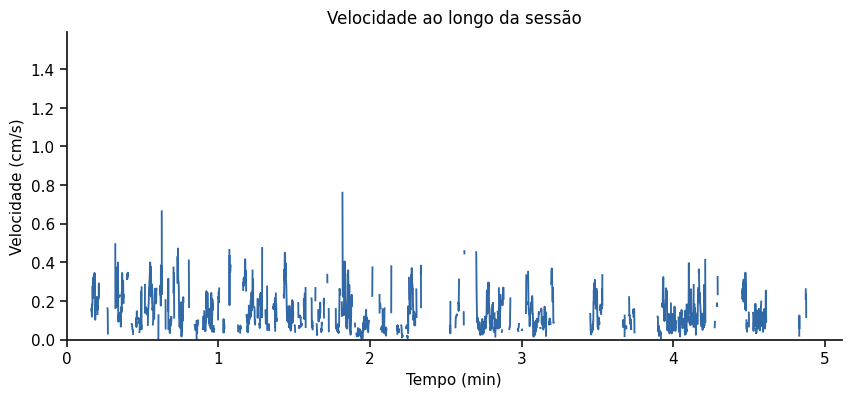

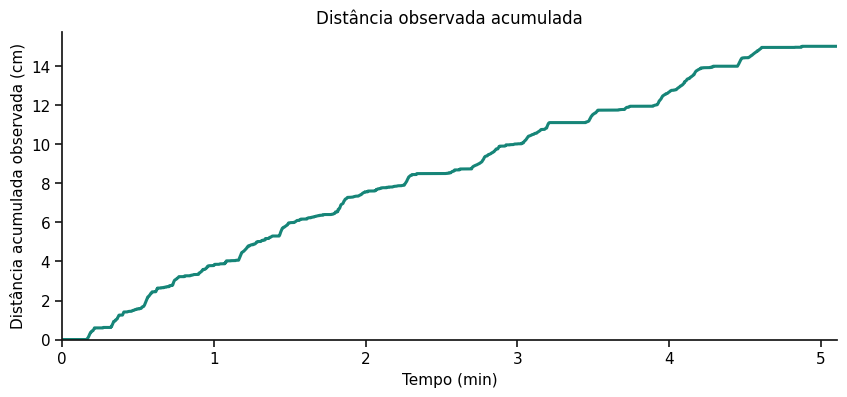

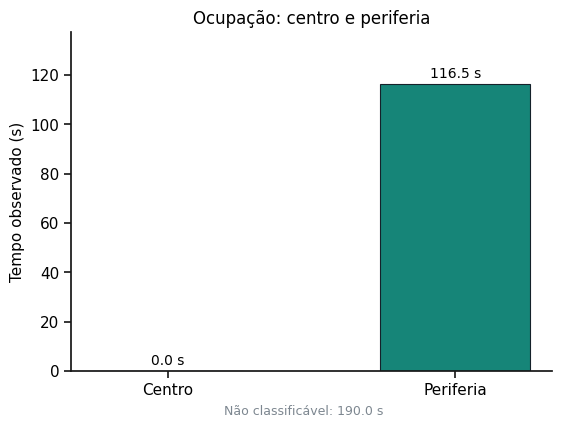

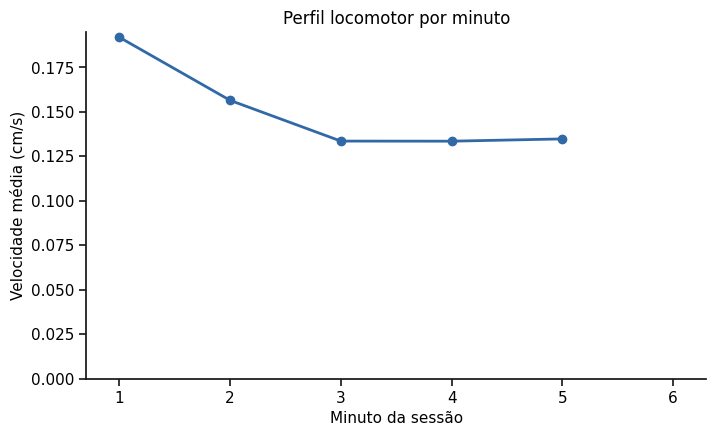

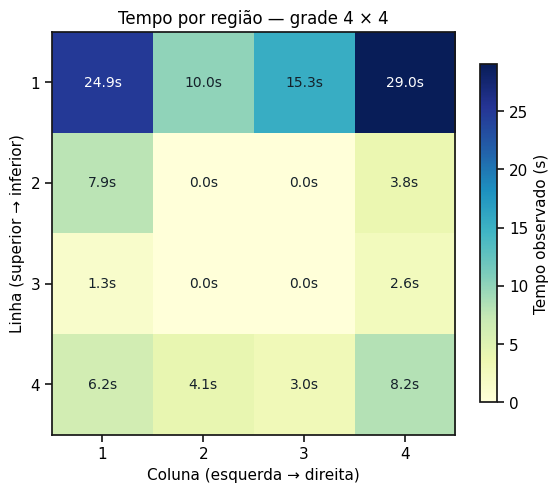

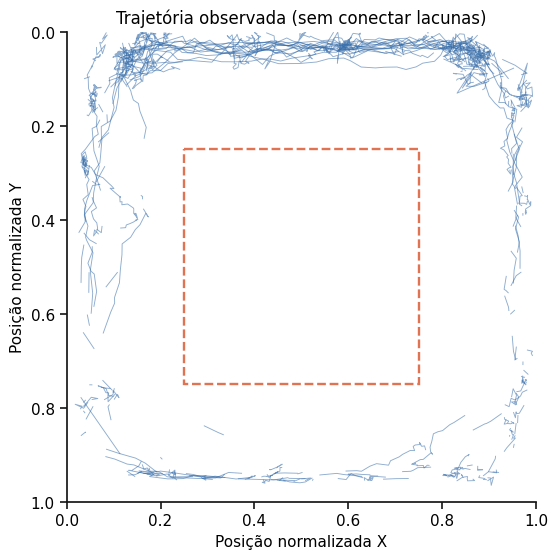

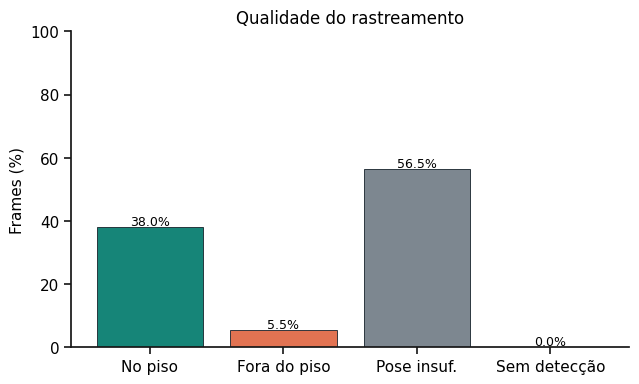

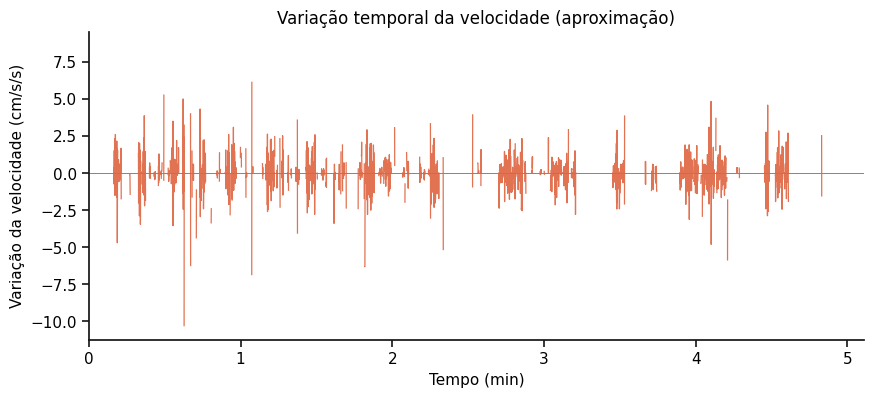

Concluído: /content/drive/MyDrive/DeepLabCut/Wistar/teste_M_openfield_completo/rat02track_e1f5f99d6726


,video,frames,fps,duracao_total_s,tracking_centro_no_piso_pct,tracking_centro_no_piso_s,tempo_sem_posicao_piso_s,frames_centro_fora_piso,frames_bbox_detectada,tempo_centro_observado_s,...,velocidade_unidade,velocidade_cobertura_pct,entradas_centro_conservadoras,calibracao_cm,largura_cm,altura_cm,limiar_likelihood,rearing,freezing,tempo_baixa_velocidade_observado_s
0,rat02track.mp4,7356,24.0,306.5,37.996194,116.458333,190.041667,402,7356,0.0,...,cm/s,32.463295,0,True,0.5,0.4,0.6,nao_calculado,nao_calculado,71.75


In [ ]:
resumos=[]
for s in SESSOES:
    print('\n\n###',s['source'].name)
    traj,resumo,occ,permin,entries,low_eps=compute_metrics(s)
    out=s['out']
    traj.to_csv(out/'metricas_frame_a_frame.csv',index=False)
    occ.to_csv(out/'ocupacao_4x4.csv',index=False)
    permin.to_csv(out/'metricas_por_minuto.csv',index=False)
    entries.to_csv(out/'entradas_centro.csv',index=False)
    low_eps.to_csv(out/'episodios_baixa_velocidade.csv',index=False)
    event_windows(traj,s['fps']).to_csv(out/'episodios_variacao_ritmo.csv',index=False)
    (out/'resumo.json').write_text(json.dumps(resumo,ensure_ascii=False,indent=2),encoding='utf-8')
    pd.DataFrame([{k:v for k,v in resumo.items() if not isinstance(v,(list,dict))}]).to_csv(out/'resumo.csv',index=False)
    scientific_graphs(s,traj,resumo,occ,permin)
    s['traj']=traj;s['resumo']=resumo
    resumos.append({k:v for k,v in resumo.items() if not isinstance(v,(list,dict))})
    print('Concluído:',out)

tabela_geral=pd.DataFrame(resumos)
tabela_geral.to_csv(OUT_DIR/'RESUMO_DA_SESSAO.csv',index=False)
display(tabela_geral)

## 8 — Experimento: candidatos a rearing por geometria + bounding box + pose parcial

**Não é detector validado.** O escore serve somente para identificar instantes suspeitos para auditoria humana. Considera proporção da caixa, distância ao limite do piso, mudanças no comprimento projetado focinho–base da cauda e pose parcialmente visível. **O escore não é uma probabilidade calibrada.** Sem referências validadas nesse vídeo, nenhum evento deve ser contabilizado como rearing confirmado.

Janelas candidatas (NÃO confirmadas): 2


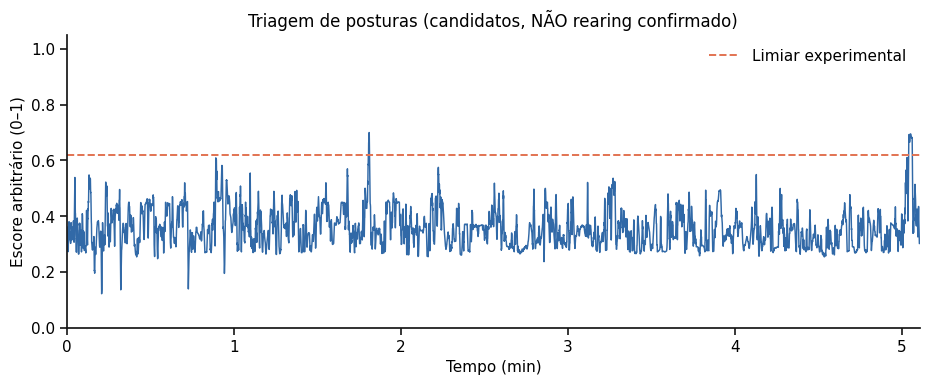

In [ ]:
from scipy.ndimage import median_filter, gaussian_filter1d

def pcol(pose,bp,key):
    try: return coluna_pose(pose,bp,key)
    except (KeyError,AssertionError): return np.full(len(pose),np.nan)

def compute_rearing_candidates(s):
    n=s['n'];fps=s['fps'];pose=s['pose'];boxes=s['boxes'];traj=s['traj'];g=s['geometry'];
    floor=np.asarray(g['floor_corners_px'],dtype=np.float32)
    H=cv2.getPerspectiveTransform(floor,np.array([[0,0],[1,0],[1,1],[0,1]],dtype=np.float32))
    bx=boxes['x'].to_numpy(float);by=boxes['y'].to_numpy(float)
    bw=boxes['w'].to_numpy(float);bh=boxes['h'].to_numpy(float)
    hasbox=boxes['observed'].to_numpy(bool) & np.isfinite(bx+bw+by+bh) & (bw>3)&(bh>3)
    aspect=np.divide(bh,np.maximum(bw,1),out=np.full(n,np.nan),where=hasbox)
    bxmid=bx+bw/2;bymid=by+bh/2
    uv=cv2.perspectiveTransform(np.c_[bxmid,bymid].astype(np.float32).reshape(-1,1,2),H).reshape(-1,2)
    d_wall=np.nanmin(np.c_[uv[:,0],1-uv[:,0],uv[:,1],1-uv[:,1]],axis=1)
    d_wall=np.where(hasbox,np.clip(d_wall,-1,1),np.nan)
    nearwall=hasbox & (d_wall<.17)
    outside=traj['estado_tracking'].to_numpy()=='centro_fora_piso'
    conf_nose=pcol(pose,'nose','likelihood'); conf_tail=pcol(pose,'tail_base','likelihood'); conf_mid=pcol(pose,'mid_back','likelihood')
    nose=np.c_[pcol(pose,'nose','x'),pcol(pose,'nose','y')]
    tail=np.c_[pcol(pose,'tail_base','x'),pcol(pose,'tail_base','y')]
    length=np.linalg.norm(nose-tail,axis=1)
    good=np.isfinite(length) & (conf_nose>=CONFIANCA_POSE) & (conf_tail>=CONFIANCA_POSE)
    length=np.where(good,length,np.nan)
    # Referência extraída apenas de frames com pose visível e centro dentro do piso,
    # evitando depender dos frames precisamente problemáticos. Não representa comprimento 3D.
    reference_pool=good & traj['centro_dentro_piso'].to_numpy(bool) & hasbox
    reference=float(np.nanmedian(length[reference_pool])) if reference_pool.any() else np.nan
    compression=np.where(good & np.isfinite(reference) & (reference>0),np.clip(1-length/reference,0,1),np.nan)
    # Alterações de aspecto vs. referência da mesma gravação, não assumir que bbox vertical = rato em pé.
    aspect_base=float(np.nanmedian(aspect[reference_pool])) if reference_pool.any() else np.nan
    aspect_shift=np.where(hasbox & np.isfinite(aspect_base) & (aspect_base>0),
                          np.clip(np.abs(np.log(np.maximum(aspect,1e-6)/aspect_base))/1.0,0,1), np.nan)
    # Penalizar quando bbox sem qualidade; perder um keypoint não prova rearing.
    n_pose=np.zeros(n,dtype=int)
    for bp in ['nose','neck','mid_back','mouse_center','tail_base','left_ear','right_ear']:
        lk=pcol(pose,bp,'likelihood');n_pose+=np.isfinite(lk)&(lk>=CONFIANCA_POSE)
    # Parede próxima é contexto, não diagnóstico; score explícito não calibrado.
    score=(0.25*nearwall.astype(float)+0.25*outside.astype(float)+
           0.30*np.nan_to_num(compression,nan=0.0)+
           0.20*np.nan_to_num(aspect_shift,nan=0.0))
    # Escore recalibrado para 0–1 apenas para legibilidade visual; não é probabilidade.
    sm=pd.Series(score).rolling(7,center=True,min_periods=4).mean().to_numpy()
    minframes=max(1,int(np.ceil(DURACAO_MIN_CANDIDATO_S*fps)))
    raw=hasbox&(sm>=LIMIAR_CANDIDATO)
    cand=np.zeros(n,dtype=bool)
    for group in groups_contiguous(raw):
        if len(group)>=minframes:cand[group]=True
    status=np.where(~hasbox,'sem_bbox',np.where(cand,'candidato_rearing',np.where(sm>=0.45,'revisar','sem_evidencia_suficiente')))
    result=pd.DataFrame({'frame':np.arange(n),'tempo_s':np.arange(n)/fps,
       'score_triagem_nao_calibrado':sm,'status_triagem':status,
       'bbox_x':bx,'bbox_y':by,'bbox_w':bw,'bbox_h':bh,'bbox_aspect_ratio':aspect,
       'distancia_borda_piso_uv':d_wall,'proximo_parede':nearwall,'centro_fora_piso_com_pose':outside,
       'n_pontos_anatomicos_validos':n_pose,'comprimento_focinho_cauda_px':length,
       'referencia_focinho_cauda_px':reference,'compressao_relativa':compression,'mudanca_aspecto_bbox':aspect_shift})
    episodes=[]
    for group in groups_contiguous(cand):
        episodes.append(dict(inicio_s=float(group[0]/fps),fim_s_exclusivo=float((group[-1]+1)/fps),
                             duracao_s=float(len(group)/fps),frame_inicio=int(group[0]),frame_fim=int(group[-1]),
                             score_mediano=float(np.nanmedian(sm[group])),
                             tipo='CANDIDATO_A_REVISAR_NAO_CONFIRMADO'))
    ep=pd.DataFrame(episodes,columns=['inicio_s','fim_s_exclusivo','duracao_s','frame_inicio','frame_fim','score_mediano','tipo'])
    return result,ep

for s in SESSOES:
    if GERAR_CANDIDATOS_REARING:
        candidate,eps=compute_rearing_candidates(s)
    else:
        candidate=pd.DataFrame({'frame':np.arange(s['n']),'status_triagem':['desativado']*s['n']})
        eps=pd.DataFrame(columns=['inicio_s','fim_s_exclusivo','duracao_s','frame_inicio','frame_fim','score_mediano','tipo'])
    s['rearing_candidate']=candidate
    candidate.to_csv(s['out']/'triagem_candidatos_rearing_PARA_REVISAR.csv',index=False)
    eps.to_csv(s['out']/'episodios_candidatos_NAO_CONFIRMADOS.csv',index=False)
    print('Janelas candidatas (NÃO confirmadas):',len(eps))
    prism_style()
    fig,ax=plt.subplots(figsize=(11,3.8))
    if 'score_triagem_nao_calibrado' in candidate:
        ax.plot(candidate.tempo_s/60,candidate.score_triagem_nao_calibrado,linewidth=1.05,color=C_BLUE)
        ax.axhline(LIMIAR_CANDIDATO,color=C_ORANGE,ls='--',lw=1.4,label='Limiar experimental')
        ax.legend(frameon=False,loc='upper right')
    ax.set(xlabel='Tempo (min)',ylabel='Escore arbitrário (0–1)',title='Triagem de posturas (candidatos, NÃO rearing confirmado)')
    ax.set_xlim(0,s['n']/s['fps']/60);ax.set_ylim(0,1.05);clean_axes(ax)
    save_fig(fig,s['out'],'09_triagem_rearing_EXPERIMENTAL')


## 9 — Renderizar vídeo completo (texto em barra acima do frame)

O frame original é mantido integralmente. A faixa superior contém número do frame, segundos, **estado de tracking** e **candidato a rearing (não confirmado)**. Cores: **verde = candidato**, **azul = sem evidência**, **amarelo = revisar**, **cinza = sem detecção**. O vídeo não mede com segurança apoio anterior ou rearing definitivo.

In [ ]:
from IPython.display import Video

def render_auditoria(s,inicio_s,duracao_s,outpath):
    n=s['n'];fps=s['fps'];frame_step=FPS_ANALISE//FPS_VIDEO_ANOTADO
    start=max(0,int(round(inicio_s*fps))); end=min(n,int(round((inicio_s+duracao_s)*fps)))
    if start>=end:return None
    w=s['w'];h=s['h'];top=int(ALTURA_BARRA_SUPERIOR_PX)
    floor=np.asarray(s['geometry']['floor_corners_px'],dtype=np.int32)
    rim=s['geometry'].get('box_rim_corners_px')
    ov=[np.asarray(p,dtype=np.int32) for p in s['geometry'].get('occlusion_polygons',[])]
    cand=s['rearing_candidate'];boxes=s['boxes'];traj=s['traj'];pose=s['pose']
    cx=pcol(pose,'mouse_center','x');cy=pcol(pose,'mouse_center','y');lk=pcol(pose,'mouse_center','likelihood')
    cap=cv2.VideoCapture(str(s['video'])); assert cap.isOpened()
    cap.set(cv2.CAP_PROP_POS_FRAMES,start)
    output=str(outpath)
    writer=cv2.VideoWriter(output,cv2.VideoWriter_fourcc(*'mp4v'),FPS_VIDEO_ANOTADO,(w,h+top))
    assert writer.isOpened(), f'Falha ao iniciar MP4: {output}'
    color={'candidato_rearing':(50,210,55),'sem_evidencia_suficiente':(230,160,65),
           'revisar':(55,205,245),'sem_bbox':(140,140,140),'desativado':(180,180,180)}
    loop_count=0
    for i in range(start,end):
        ok,img=cap.read()
        if not ok:raise RuntimeError(f'Vídeo terminou antecipadamente no frame {i}/{end}')
        if (i-start)%frame_step:continue
        cv2.polylines(img,[floor],True,(60,175,75),2)
        if rim is not None:cv2.polylines(img,[np.asarray(rim,dtype=np.int32)],True,(225,195,75),2)
        for p in ov:cv2.polylines(img,[p],True,(200,90,200),2)
        status=cand.status_triagem.iloc[i];col=color.get(status,(175,175,175))
        b=boxes.iloc[i]
        if bool(b.observed) and np.isfinite([b.x,b.y,b.w,b.h]).all():
            x1,y1,x2,y2=round(b.x),round(b.y),round(b.x+b.w),round(b.y+b.h)
            cv2.rectangle(img,(x1,y1),(x2,y2),col,3)
        if np.isfinite([cx[i],cy[i],lk[i]]).all() and lk[i]>=CONFIANCA_POSE:
            cv2.circle(img,(round(cx[i]),round(cy[i])),4,(20,20,230),-1)
        # Banner separado, não cobre nem o topo nem o canto inferior do vídeo.
        canvas=np.full((h+top,w,3),(24,31,39),np.uint8)
        canvas[top:,:,:]=img
        cv2.putText(canvas,f'{s["source"].stem[:40]}  |  {i/fps:7.2f} s  |  frame {i}/{n-1}',
                    (22,36),cv2.FONT_HERSHEY_SIMPLEX,.78,(255,255,255),2,cv2.LINE_AA)
        cv2.putText(canvas,f'Pose: {str(traj.estado_tracking.iloc[i])}  |  Triagem: {status}',
                    (22,73),cv2.FONT_HERSHEY_SIMPLEX,.68,col,2,cv2.LINE_AA)
        cv2.putText(canvas,'REARING: triagem exploratoria, NAO comportamento validado',
                    (22,104),cv2.FONT_HERSHEY_SIMPLEX,.53,(205,216,226),1,cv2.LINE_AA)
        writer.write(canvas);loop_count+=1
        if loop_count%400==0:print('Renderizado:',loop_count,'frames do arquivo de auditoria')
    writer.release();cap.release()
    return outpath

for s in SESSOES:
    if GERAR_PREVIEW:
        target=s['out']/'PREVIA_20s_com_barra.mp4'
        if RENDERIZAR_NOVAMENTE or not target.is_file():render_auditoria(s,PREVIEW_INICIO_S,PREVIEW_DURACAO_S,target)
        print('Prévia:',target)
    if GERAR_VIDEO_COMPLETO_ANOTADO:
        target=s['out']/'VIDEO_COMPLETO_com_barra_e_triagem.mp4'
        if RENDERIZAR_NOVAMENTE or not target.is_file():render_auditoria(s,0,s['n']/s['fps'],target)
        print('Vídeo completo:',target)


Prévia: /content/drive/MyDrive/DeepLabCut/Wistar/teste_M_openfield_completo/rat02track_e1f5f99d6726/PREVIA_20s_com_barra.mp4
Renderizado: 400 frames do arquivo de auditoria
Renderizado: 800 frames do arquivo de auditoria
Renderizado: 1200 frames do arquivo de auditoria
Renderizado: 1600 frames do arquivo de auditoria
Renderizado: 2000 frames do arquivo de auditoria
Renderizado: 2400 frames do arquivo de auditoria
Renderizado: 2800 frames do arquivo de auditoria
Renderizado: 3200 frames do arquivo de auditoria
Renderizado: 3600 frames do arquivo de auditoria
Vídeo completo: /content/drive/MyDrive/DeepLabCut/Wistar/teste_M_openfield_completo/rat02track_e1f5f99d6726/VIDEO_COMPLETO_com_barra_e_triagem.mp4


## 10 — Relatório, arquivos finais e download

Abreviações: `triagem` = suspeitas para revisão, `centro_fora_piso` = pose preservada mas posição no plano do chão indefinida. A análise pode ser repetida com novos JSONs sem repetir inferência; arquivos diferentes ficam em pastas distintas.

In [ ]:
for s in SESSOES:
    out=s['out']
    summary=dict(s['resumo'])
    summary['rearing_confirmado']='NAO_ESTIMADO'
    summary['n_candidatos_rearing_nao_validados']=int(pd.read_csv(out/'episodios_candidatos_NAO_CONFIRMADOS.csv').shape[0])
    summary['tem_borda_caixa']=s['geometry'].get('box_rim_corners_px') is not None
    summary['n_poligonos_oclusao']=len(s['geometry'].get('occlusion_polygons',[]))
    (out/'RESUMO_GERAL_TESTE_M.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
    note=('Teste M | '+str(s['source'].name)+'\n\n'
          +'Arquivo fonte: '+str(s['source'])+'\n'
          +'Frames: '+str(s['n'])+' | FPS analise: '+str(s['fps'])+'\n\n'
          +'Rearing: SOMENTE candidatos para revisao, NAO confirmados.\n'
          +'Tracking perdido nao e imobilidade. Distancia subestima trechos sem tracking.\n')
    (out/'LEIA_ME_PRIMEIRO.txt').write_text(note,encoding='utf-8')
    pack=out/'TESTE_M_TABELAS_E_GRAFICOS.zip'
    with zipfile.ZipFile(pack,'w',zipfile.ZIP_DEFLATED,compresslevel=4) as z:
        for p in out.iterdir():
            if p.suffix.lower() in ('.png','.svg','.csv','.json','.txt') and p.name!=pack.name:
                z.write(p,arcname=p.name)
    print('Sessão:',out)
    print('Gráficos + tabelas:',pack)
    print('Vídeo completo:',out/'VIDEO_COMPLETO_com_barra_e_triagem.mp4')
print('✅ Análise concluída. Não conte candidatos de rearing como episódios confirmados.')


In [1]:
import sys
import torch
import torchvision
import importlib.util

print("Python:", sys.version)
print("Executável:", sys.executable)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU disponível:", torch.cuda.is_available())
print("CUDA:", torch.version.cuda)
print("DeepLabCut instalado:",
      importlib.util.find_spec("deeplabcut") is not None)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Executável: /usr/bin/python3
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
GPU disponível: True
CUDA: 13.0
DeepLabCut instalado: False
